# 05 – Neural network (MLP) + distillation (proton)

## 1. Introduction

Instead of formulas, here a **neural network** learns the shape, without a predefined functional form.
For every momentum, the network outputs a full probability map on the $(z', r)$ grid. It is trained with the same detector convolution and
likelihood as the GFlash formula (01), so the two are directly comparable.

**How does the MLP ("neural field") work?** The network is queried separately for every grid cell: *"what is the density at depth $z'$,
distance $r$, momentum $p$?"* The network's answers ($z'$, $r$, $\ln p$ and their sinusoidal features → $n_L$ hidden layers, $H$ neurons each → one number)
are turned into a probability map by a softmax. It acts like a **flexible, malleable map**: the network can take any smooth shape
the data demand.

**How large should the network be?** For the formulas, the degree of the $\ln p$ polynomial was chosen on the validation set (01, 4b). Here the same
protocol selects the **architecture**: several (layers, neurons) pairs are trained, and we keep the smallest one beyond which
larger networks no longer improve detectably (1-SE rule). This demonstrates that the network capacity is **sufficient**.

**Distillation (symbolic regression):** finally, the trained network is "translated" into an analytic formula: several formula families are fitted to the network maps,
and the simplest sufficiently accurate one is kept. This condenses the flexibility of the network into an interpretable formula with few parameters.

**Unified comparison (section 7):** at the end, the previous shapes (GFlash $r_{95}$, envelope, drop) and the two new shapes
(MLP $r_{95}$, distilled formula $r_{95}$) are compared with the same metric and on the same plots as in notebook 03.

> **Copy of the report notebook `05_mlp_proton.ipynb`** (shape-form). Its cells are unchanged; only the data path is absolute, and the report's
> saved models are loaded from `results/`. **Section 8** adds the shower-shape formula of shape-form-particle next to the network and its distilled formula.

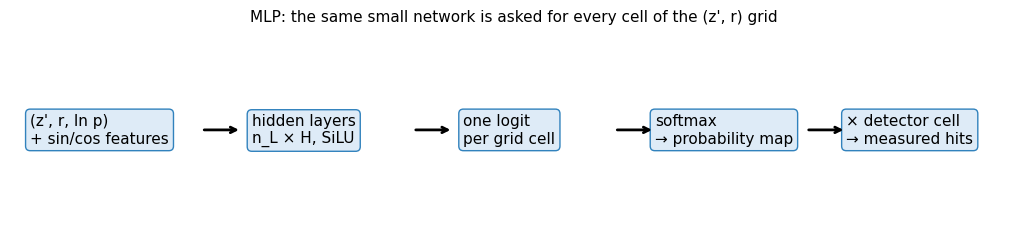

In [1]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(13, 2.6)); ax.axis("off")
boxes = [("(z', r, ln p)\n+ sin/cos features", 0.02), ("hidden layers\nn_L × H, SiLU", 0.24), ("one logit\nper grid cell", 0.45),
         ("softmax\n→ probability map", 0.64), ("× detector cell\n→ measured hits", 0.83)]
for txt, x in boxes:
    ax.text(x, 0.5, txt, ha="left", va="center", fontsize=11, bbox=dict(boxstyle="round", fc="#deebf7", ec="#3182bd"))
for x in (0.19, 0.40, 0.60, 0.79):
    ax.annotate("", xy=(x + 0.04, 0.5), xytext=(x, 0.5), arrowprops=dict(arrowstyle="->", lw=2))
ax.set_title("MLP: the same small network is asked for every cell of the (z', r) grid", fontsize=11)
plt.show()

## 2. Loading the data

In [2]:
PARTICLES = ['proton']
DATA_DIR = "/home/user/data/simulations/regression-proton/"          # a CSV-k helye
OUT_DIR = "results"        # models and exports are stored here
%run -i ./00_common.ipynb

/home/user/.venv/lib/python3.10/site-packages/nbformat/__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


device: cuda | data: /home/user/data/simulations/regression-proton/ | output: results


In [3]:
DATA = {}
for particle in PARTICLES:
    df, geo, DATA[particle] = load_data(particle)
    print(f"\n===== {particle} =====")
    df.info()
    display(df.describe().T)
    display(df.head())

proton: 99925 events, geometry {'layer': 20.5, 'cell': 48.59999999999991, 'z_back': 4882.15}, split train 69946, val 14987, test 14992

===== proton =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54740548 entries, 0 to 54740547
Data columns (total 21 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   event_number                int64  
 1   cellID                      int64  
 2   x                           float64
 3   y                           float64
 4   z                           float64
 5   x_local                     float64
 6   y_local                     float64
 7   z_local                     float64
 8   x_trans                     float64
 9   y_trans                     float64
 10  z_trans                     float64
 11  energy                      float64
 12  earliest_contribution_time  float64
 13  incoming_momentum           float64
 14  incoming_theta              float64
 15  incoming_phi                

,count,mean,std,min,25%,50%,75%,max
event_number,54740548.0,1.061527e+05,7.737650e+04,3.000000e+00,5.248700e+04,1.050650e+05,1.577730e+05,2.119982e+06
cellID,54740548.0,2.078115e+09,1.471819e+09,4.212000e+03,7.136951e+08,1.745523e+09,3.306567e+09,5.063386e+09
x,54740548.0,8.340518e+00,1.308310e+03,-2.596035e+03,-1.032024e+03,3.040900e+01,1.041428e+03,2.601035e+03
y,54740548.0,-3.721223e+00,1.311835e+03,-2.599800e+03,-1.036200e+03,-2.620000e+01,1.036200e+03,2.599800e+03
z,54740548.0,4.087755e+03,2.839532e+02,3.662400e+03,3.867400e+03,4.031400e+03,4.277400e+03,4.871900e+03
x_local,54740548.0,-4.207020e+01,2.241171e+02,-4.896420e+03,-1.444550e+02,-3.088325e+01,6.947679e+01,2.979718e+03
y_local,54740548.0,1.054415e-01,2.235098e+02,-3.319625e+03,-1.091375e+02,0.000000e+00,1.090265e+02,3.238695e+03
z_local,54740548.0,4.406571e+02,3.025983e+02,-2.931879e+03,2.039936e+02,3.921629e+02,6.374536e+02,2.667495e+03
x_trans,54740548.0,6.120635e-02,2.520863e+02,-4.887696e+03,-1.398834e+02,0.000000e+00,1.412087e+02,5.140408e+03
y_trans,54740548.0,3.625353e-03,2.520673e+02,-4.894655e+03,-1.405741e+02,0.000000e+00,1.403782e+02,5.147369e+03


,event_number,cellID,x,y,z,x_local,y_local,z_local,x_trans,y_trans,...,energy,earliest_contribution_time,incoming_momentum,incoming_theta,incoming_phi,incoming_momentum_bin,particle_type,is_secondary,parent_type,daughter_type
0,186640,2823563636,-1387.531982,-2147.199951,4379.899902,-130.723225,-378.459188,761.351211,-463.007620,-103.890706,...,4.238810e-08,1200.353271,17.044954,0.549644,-1.997623,17,neutron,1,neutron,gamma;gamma
1,132450,163584116,132.927994,2551.199951,4277.399902,69.697194,210.840800,750.914462,-152.802091,460.011513,...,6.959773e-08,574.963501,13.259551,0.524659,1.441496,13,neutron,1,neutron,proton;proton
2,1436,2307335028,-830.135010,-175.800003,4359.399902,-226.855893,-0.924198,665.431786,90.170637,18.004689,...,6.916019e-04,14.909340,16.654422,0.197399,-2.954562,16,proton,1,neutron,e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e...
3,118990,608834164,835.135010,-1339.199951,3887.899902,-119.737264,179.827552,193.795084,146.963886,108.548892,...,1.211111e-08,1620.073486,19.433977,0.411175,-1.112347,19,neutron,1,neutron,NaN
4,49113,4412592500,984.348999,1440.199951,4236.399902,-218.178821,-147.723526,531.631196,141.541496,-50.457615,...,2.290001e-05,165.507782,17.042273,0.437355,1.044127,17,neutron,1,neutron,gamma;gamma;gamma


## 3. The model

### What do we fit, and what affects training?

**Input:** only $\ln p$ (`incoming_momentum`); the network additionally receives the grid cell position ($z'$, $r$ and their sine/cosine features).
**Output:** the full $(z', r)$ map. Training minimises the same likelihood as for the formulas, so the fitted features are the same:
- $z'$ = `z_local`, $r$ = `hypot(x_local, y_local)`, weight `energy` (normalised per event), grouped by `event_number`.
- **Affected by:** the detector convolution (`incoming_theta`, `incoming_phi`, cell size), the back-face truncation ($z_b$ from the `z`, `z_trans` columns), the cuts.

**What differs from the formulas:**
- There is no prescribed functional form, so the shape is limited by **the grid resolution and the network architecture**. The number of layers ($n_L$) and
  neurons ($H$) are chosen in section 4; the number of frequencies is fixed (4).
- **Smoothness penalty** (`smooth=1e-4`): the second difference of $\log P$ along depth. It sets the "stiffness" of the network.
- **Beyond the back face** and **below the cell scale** the data do not constrain the network: there the output is set by the architecture and the penalty (artefacts are possible).
- Training: `epochs=60`, `lr=3e-3`, Adam, early stopping on the validation NLL (`patience=15`).

In [4]:
class FieldModel(nn.Module):
    """MLP(z', r, ln p) -> logit for every grid cell -> softmax."""

    def __init__(self, hidden=64, n_layers=3, n_freq=4):
        super().__init__()
        zn = (ZZ - Z_MIN) / (Z_MAX - Z_MIN) * 2 - 1          # depth scaled to [-1, 1]
        rn = torch.sqrt(RR / R_MAX)                            # radius, stretched near the axis
        feats = [zn, rn]
        for k in range(1, n_freq + 1):                         # sin/cos features: help to learn sharp structures
            feats += [torch.sin(math.pi * k * zn), torch.cos(math.pi * k * zn),
                      torch.sin(math.pi * k * rn), torch.cos(math.pi * k * rn)]
        self.register_buffer("static", torch.stack(feats, -1))
        layers, d = [], self.static.shape[-1] + 1
        for _ in range(n_layers):
            layers += [nn.Linear(d, hidden), nn.SiLU()]
            d = hidden
        self.mlp = nn.Sequential(*layers, nn.Linear(d, 1))

    def forward(self, lnp):
        x = torch.cat([self.static[None].expand(len(lnp), -1, -1, -1),
                       (lnp / 3)[:, None, None, None].expand(-1, N_Z, N_R, 1)], -1)
        logits = self.mlp(x).squeeze(-1)
        return F.log_softmax(logits.reshape(len(lnp), -1), 1).reshape(len(lnp), N_Z, N_R)


make_model = lambda hidden=64, n_layers=3: FieldModel(hidden, n_layers).to(DEVICE)
arch_label = lambda cfg: f"L{cfg['n_layers']}xH{cfg['hidden']}"

print("parameters (L3xH64):", sum(p.numel() for p in make_model().parameters()))

parameters (L3xH64): 9665


## 4. Training and architecture selection

Same protocol as the degree selection for the formulas (common notebook, section 7, `select_architecture`):
- **train:** network weights; **validation:** early stopping and architecture selection; **test:** evaluation of the final network only.
- **Rule:** we compute the per-event paired difference relative to the architecture with the lowest validation NLL ($c^*$); the network with the **fewest
  parameters** whose difference is within one standard error is chosen.

The search has two stages (instead of a full grid, to save run time):
1. **Width:** $H \in \{16, 32, 64, 128, 256\}$, with 3 hidden layers.
2. **Depth (4b):** $n_L \in \{1, 2, 3, 4, 5\}$ with the chosen width.

Every network is saved to `results/proton/mlp_L<n_L>xH<H>.pt`; a completed training is only loaded.

**What to look for:** if the chosen network is at the **edge** of the range (largest $H$ or $n_L$), the search must be extended,
because sufficient capacity is not demonstrated. If it is inside and the curve flattens for larger networks, the capacity is saturated.

--- L3xH16 ---


loaded finished model from results/proton/mlp_L3xH16.pt


--- L3xH32 ---
loaded finished model from results/proton/mlp_L3xH32.pt


--- L3xH64 ---
loaded finished model from results/proton/mlp_L3xH64.pt


--- L3xH128 ---
loaded finished model from results/proton/mlp_L3xH128.pt


--- L3xH256 ---
loaded finished model from results/proton/mlp_L3xH256.pt


lowest validation NLL: L3xH32;  chosen by the 1-SE rule: L3xH16


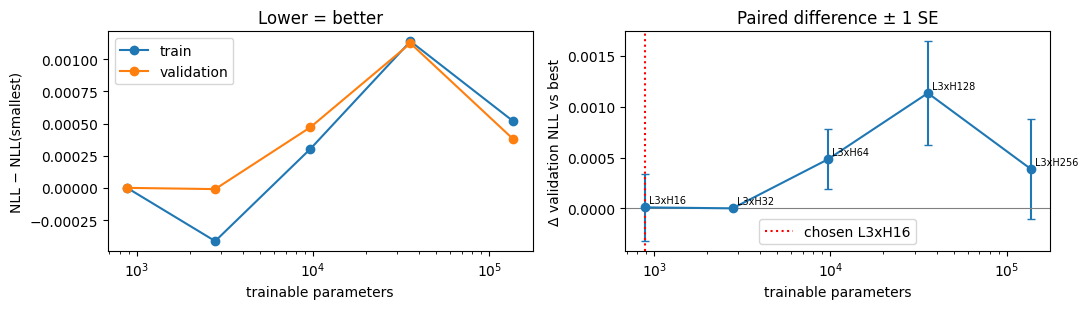

,n_layers,hidden,params,train NLL,val NLL,epochs,Δval vs best,SE,chosen
config,,,,,,,,,
L3xH16,3,16,881,18.1747,18.1958,51,0.0000,0.0003,◀
L3xH32,3,32,2785,18.1742,18.1957,51,0.0000,0.0000,
L3xH64,3,64,9665,18.1750,18.1962,51,0.0005,0.0003,
L3xH128,3,128,35713,18.1758,18.1969,24,0.0011,0.0005,
L3xH256,3,256,136961,18.1752,18.1961,35,0.0004,0.0005,


In [5]:
particle = "proton"
data = DATA[particle]
WIDTHS = [dict(n_layers=3, hidden=h) for h in (16, 32, 64, 128, 256)]
cfg_w, TAB_W, MODELS_W = select_architecture(make_model, WIDTHS, data, particle, "mlp", epochs=60, lr=3e-3, smooth=1e-4, label=arch_label)
display(TAB_W.round(4))

## 4b. Choosing the number of layers

With the chosen width, the number of layers is varied. The 3-layer network is loaded from the previous step.

--- L1xH16 ---
loaded finished model from results/proton/mlp_L1xH16.pt


--- L2xH16 ---
loaded finished model from results/proton/mlp_L2xH16.pt


--- L3xH16 ---
loaded finished model from results/proton/mlp_L3xH16.pt


--- L4xH16 ---
loaded finished model from results/proton/mlp_L4xH16.pt


--- L5xH16 ---
loaded finished model from results/proton/mlp_L5xH16.pt


lowest validation NLL: L4xH16;  chosen by the 1-SE rule: L3xH16


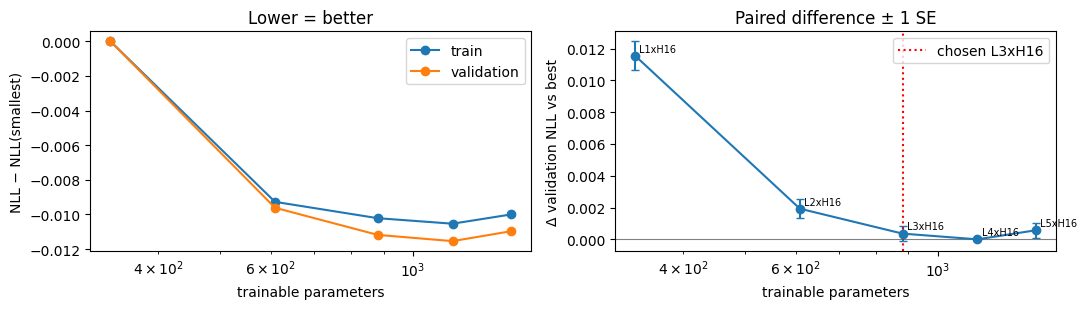

,n_layers,hidden,params,train NLL,val NLL,epochs,Δval vs best,SE,chosen
config,,,,,,,,,
L1xH16,1,16,337,18.1849,18.2069,60,0.0115,0.0009,
L2xH16,2,16,609,18.1756,18.1973,60,0.0019,0.0006,
L3xH16,3,16,881,18.1747,18.1958,51,0.0004,0.0005,◀
L4xH16,4,16,1153,18.1743,18.1954,60,0.0000,0.0000,
L5xH16,5,16,1425,18.1749,18.1960,51,0.0006,0.0005,


chosen architecture: L3xH16 | parameters: 881 | inside the search range: capacity is sufficient


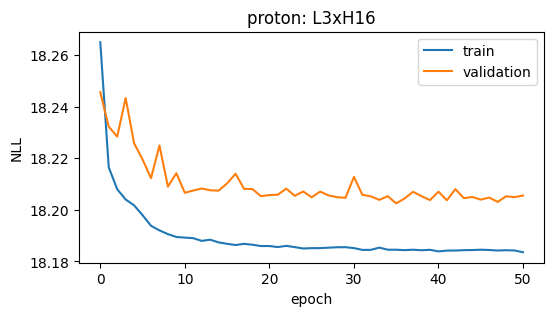

In [6]:
DEPTHS = [dict(n_layers=n, hidden=cfg_w["hidden"]) for n in (1, 2, 3, 4, 5)]
cfg, TAB_D, MODELS_D = select_architecture(make_model, DEPTHS, data, particle, "mlp", epochs=60, lr=3e-3, smooth=1e-4, label=arch_label)
display(TAB_D.round(4))
ARCH_TABLE = pd.concat([TAB_W.assign(stage="width"), TAB_D.assign(stage="depth")])
edge = cfg["hidden"] == max(c["hidden"] for c in WIDTHS) or cfg["n_layers"] == max(c["n_layers"] for c in DEPTHS)
print("chosen architecture:", arch_label(cfg), "| parameters:", int(TAB_D.loc[arch_label(cfg), "params"]),
      "| at the edge of the search range!" if edge else "| inside the search range: capacity is sufficient")

NETS = {particle: MODELS_D[arch_label(cfg)]}
hist = torch.load(f"{OUT_DIR}/{particle}/mlp_{arch_label(cfg)}.pt", weights_only=False)["history"]
plt.figure(figsize=(6, 3)); plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="validation")
plt.title(f"{particle}: {arch_label(cfg)}"); plt.xlabel("epoch"); plt.ylabel("NLL"); plt.legend(); plt.show()

## 5. Distillation

Four formula families ($\{$`gamma`, `plateau`$\} \times \{$`core_tail`, `gauss_exp`$\}$) with first- and second-degree $\ln p$ dependence are fitted
to the maps of the chosen network. We keep the simplest one within 0.005 nat KL of the best.

**Here the formula is fitted to the network maps, not to the data** (KL divergence, 30 $\ln p$ values between the 2–98% quantiles of the training data, without convolution).
The map is used only up to depth $z_{cut}$ (still in front of the back face for 90% of training events). The formula quality is therefore also affected by the network's errors and
artefacts; the test NLL shows the result measured against the data. The result is saved to `results/proton/mlp_formula.pt`.

In [7]:
CANDIDATES = [("gamma", "core_tail"), ("gamma", "gauss_exp"), ("plateau", "core_tail"), ("plateau", "gauss_exp")]
FORMULAS = {}
for particle in PARTICLES:
    print(f"===== {particle} =====")
    path = f"{OUT_DIR}/{particle}/mlp_formula.pt"
    if os.path.exists(path):
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
        f = Formula(ck["long"], ck["lat"], ck["degree"]).to(DEVICE)
        f.load_state_dict(ck["state"])
        print("loaded", path)
        display(ck["table"])
    else:
        f, table, z_cut = distill(NETS[particle], DATA[particle]["train"], CANDIDATES, steps=600)
        display(table.sort_values("KL"))
        torch.save({"long": f.long, "lat": f.lat, "degree": f.degree, "state": f.state_dict(), "table": table}, path)
    FORMULAS[particle] = f

===== proton =====
loaded results/proton/mlp_formula.pt


,longitudinal,lateral,degree,params,KL
0,gamma,core_tail,1,15,0.152334
1,gamma,core_tail,2,21,0.123710
2,gamma,gauss_exp,1,15,0.167956
3,gamma,gauss_exp,2,21,0.136101
4,plateau,core_tail,1,19,0.133452
5,plateau,core_tail,2,27,0.121696
6,plateau,gauss_exp,1,19,0.149459
7,plateau,gauss_exp,2,27,0.133906


## 6. Results

**What to look for:**
- **Test NLL:** whether the NLLs of the network and the formula are close. If so, the formula captures almost everything the network learned.
  Reference: the test NLL of the GFlash formula (01); the network must not be worse, otherwise it is not flexible enough or trained poorly.
- **Profiles:** both the network (orange) and the formula (red) should follow the data (black).
- **True shape and 3D:** whether the network shape is smooth. The network may learn small sub-cell artefacts (e.g. a thin spike on the axis),
  because the data do not constrain it there; the formula smooths these out.
- **Formula:** which family won, and how its parameters depend on momentum.

## proton

test NLL  GFlash (01): 18.2536
test NLL  mlp: 18.1922   formula: 18.2677   difference (paired): +0.0754 ± 0.0020


/tmp/ipykernel_1107011/1674953462.py:114: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  terms = " ".join(f"{float(v):+.4g}" + ("" if k == 0 else rf"\,{L}" if k == 1 else rf"\,{L}^{k}")


### The distilled formula (gamma × core_tail, degree 2)

$$L \propto s^{\alpha-1}e^{-(\alpha-1)s/t_{max}},\; s=z'-z_0,\; \alpha=1+e^{\mathrm{log\_am1}},\; t_{max}=e^{\mathrm{log\_tmax}}$$

$$T = \frac{p_c}{\pi}\frac{R_C^2}{(r^2+R_C^2)^2}+\frac{1-p_c}{\pi}\frac{R_T^2}{(r^2+R_T^2)^2}$$

| parameter | value, $L=\ln(p/\mathrm{GeV})$ | depth slope (× z'/1000) |
|---|---|---|
| `z0` | $-10.86 -0.9164\,L -0.7915\,L^2$ | – |
| `log_tmax` | $+3.447 +0.9509\,L -0.1695\,L^2$ | – |
| `log_am1` | $-0.717 -0.4525\,L +0.1483\,L^2$ | – |
| `log_rc` | $+2.908 +0.5094\,L -0.1793\,L^2$ | +1.316 |
| `log_ratio` | $+2.345 -1.359\,L +0.3117\,L^2$ | -1.145 |
| `logit_pc` | $+2.587 -1.257\,L +0.09154\,L^2$ | -4.915 |

Number of parameters: **21**

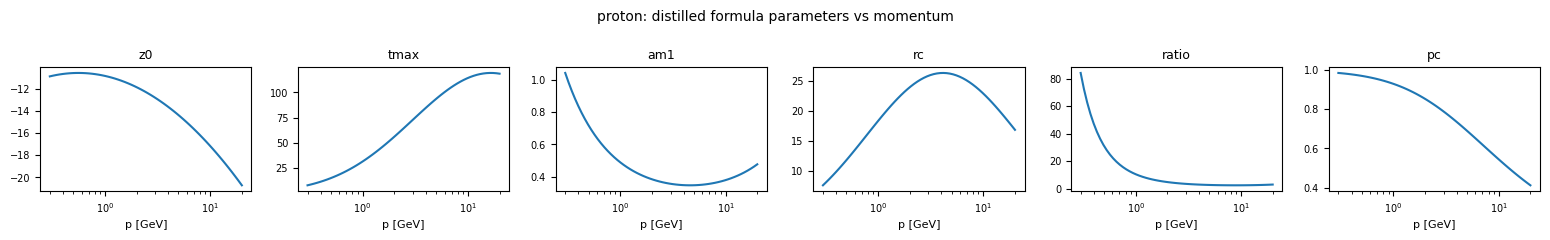

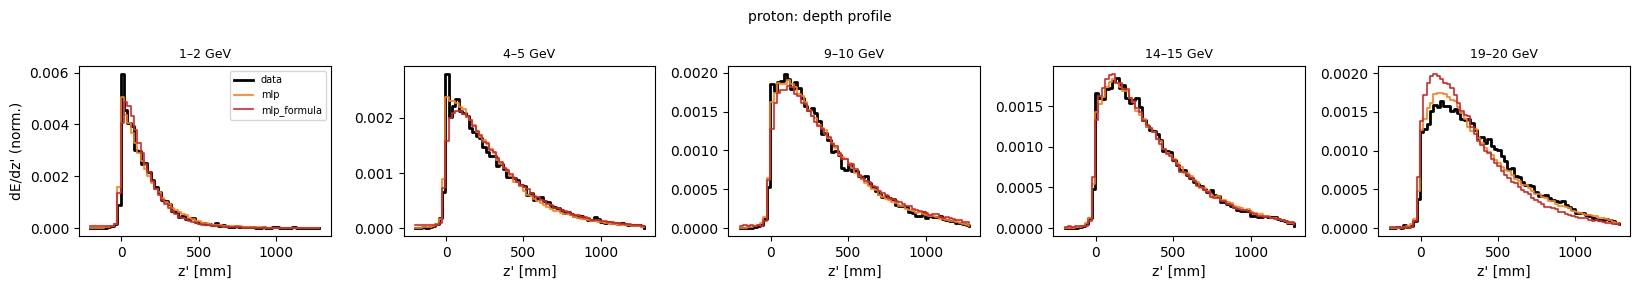

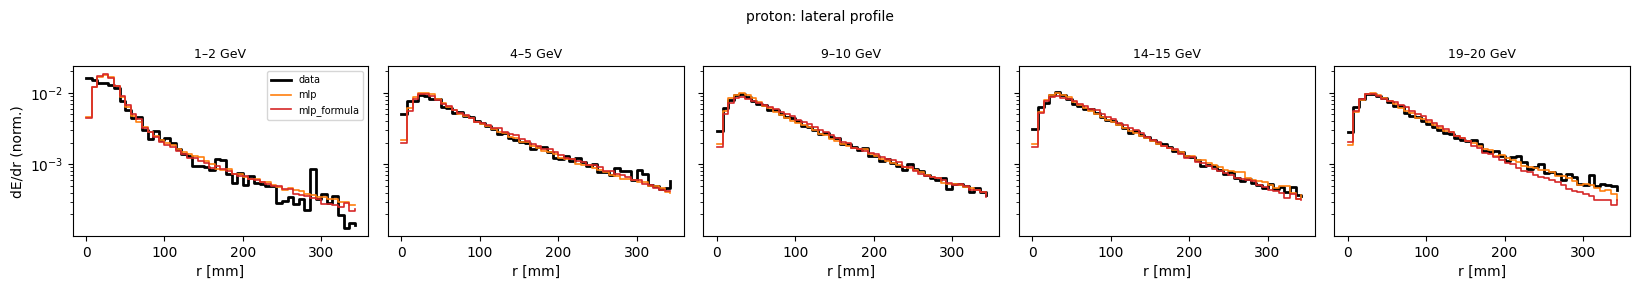

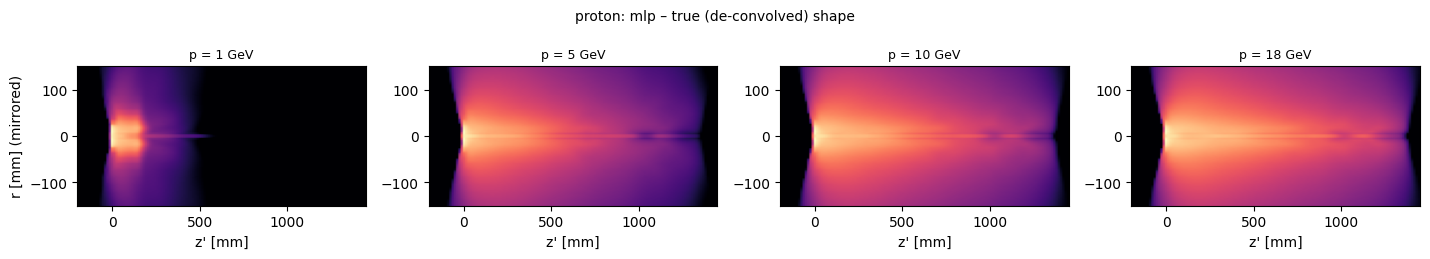

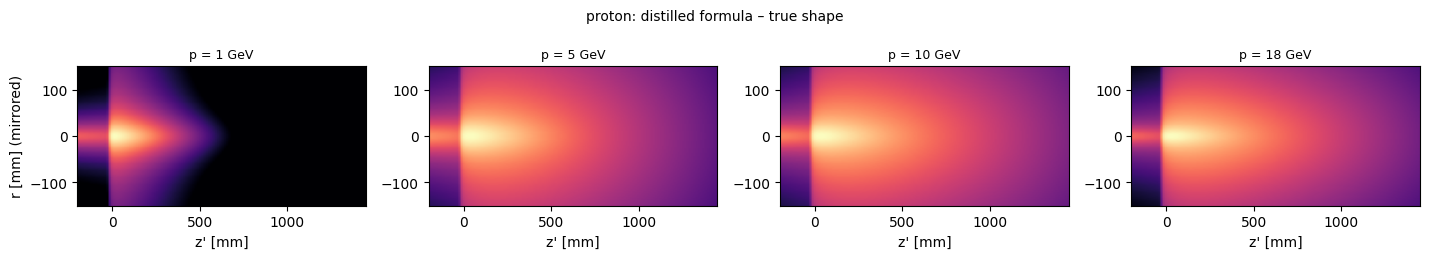

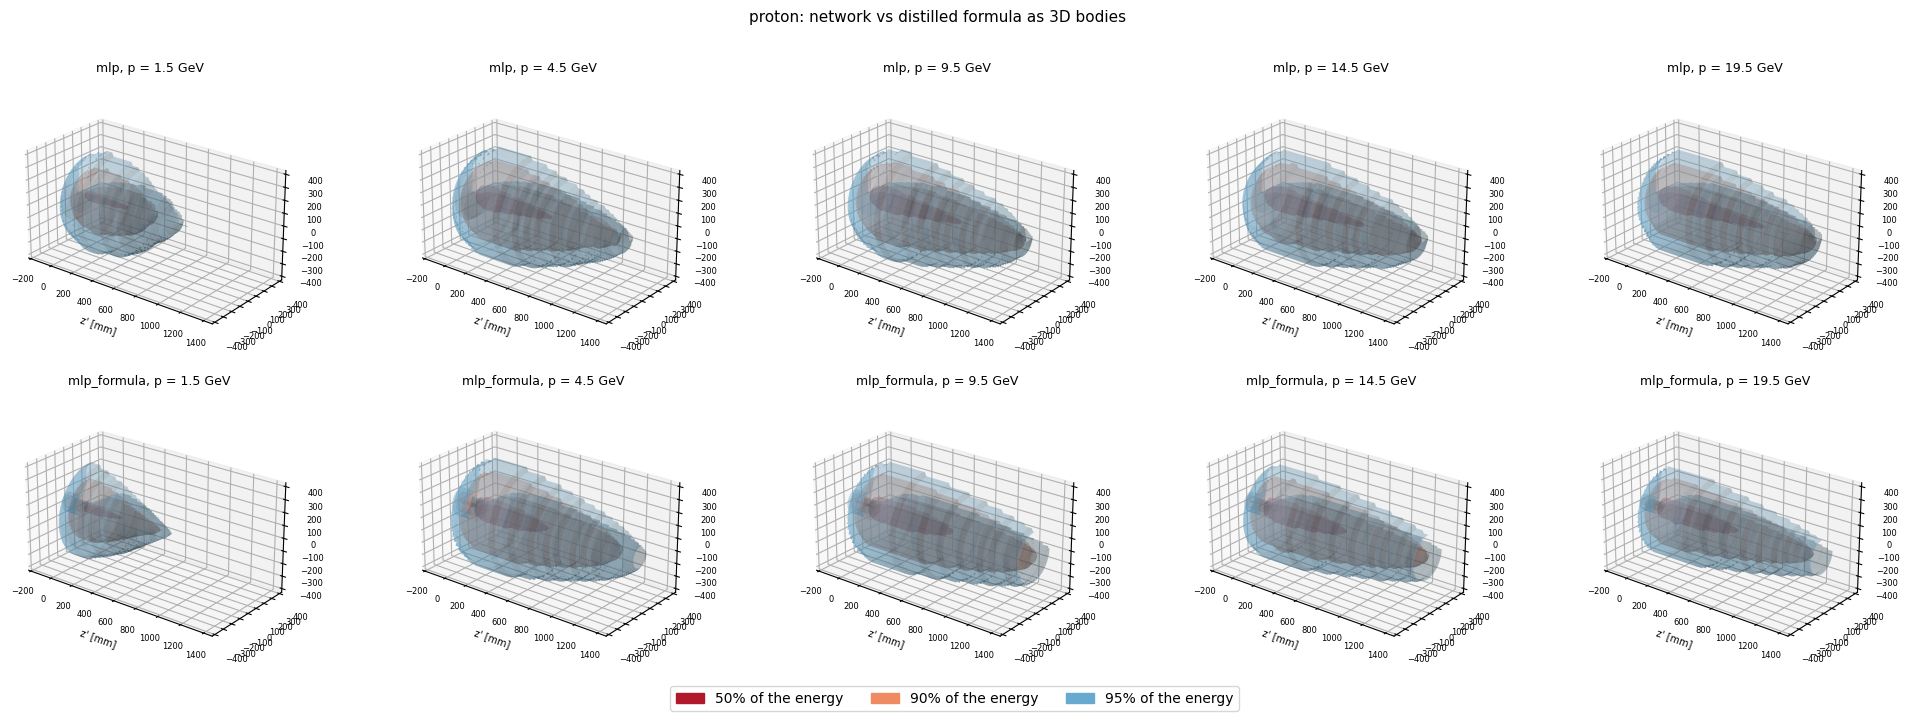

exported proton/mlp: test NLL = 18.1922
exported proton/mlp_formula: test NLL = 18.2677


In [8]:
for particle in PARTICLES:
    display(Markdown(f"## {particle}"))
    data, net, f = DATA[particle], NETS[particle], FORMULAS[particle]
    nll_net, nll_f = test_nll(net, data["test"]), test_nll(f, data["test"])
    gf_path = f"{OUT_DIR}/{particle}/export_gflash.pt"
    if os.path.exists(gf_path):
        print(f"test NLL  GFlash (01): {torch.load(gf_path, weights_only=False)['test_nll'].mean():.4f}")
    d = nll_f - nll_net
    print(f"test NLL  mlp: {nll_net.mean():.4f}   formula: {nll_f.mean():.4f}   "
          f"difference (paired): {d.mean():+.4f} ± {d.std(ddof=1) / np.sqrt(len(d)):.4f}")
    display(Markdown(f.describe(f"The distilled formula ({f.long} × {f.lat}, degree {f.degree})")))
    formula_curves(f, f"{particle}: distilled formula parameters vs momentum")
    hits = data["test"].hits()
    samples = {"mlp": sample_folded(net, data["test"]), "mlp_formula": sample_folded(f, data["test"])}
    profile_plot(hits, samples, "z", f"{particle}: depth profile")
    profile_plot(hits, samples, "r", f"{particle}: lateral profile")
    shape_map(net, title=f"{particle}: mlp – true (de-convolved) shape")
    shape_map(f, title=f"{particle}: distilled formula – true shape")
    bodies_3d({"mlp": net, "mlp_formula": f}, title=f"{particle}: network vs distilled formula as 3D bodies")
    export(particle, "mlp", net, data)
    export(particle, "mlp_formula", f, data, f.describe(f"MLP → formula ({particle})"))

## 7. Unified comparison: five shapes with the same metric

Same metric and same plots as in the comparison of notebook 03, with two new shapes:

| | formula | what it describes | parameters |
|---|---|---|---|
| **GFlash $r_{95}$** (01) | Gamma × (core + tail) | 95% energy region of the **average** shower | ~15–60 (global) |
| **Envelope** (02) | $r = A\,u^{a}e^{-bu}$ | hull sized for 98% of showers | 4 / bin |
| **Drop** (03) | $r = A\,g\!\left(\frac{z'-z_0}{L}\right)$ | same kind of hull, finite, fixed shape | 3 / bin |
| **MLP $r_{95}$** (05) | neural field | 95% energy region of the **average** shower, without a fixed form | network weights (global) |
| **MLP-formula $r_{95}$** (05) | distilled formula | the same, with a formula extracted from the network | formula parameters (global) |

**Important for interpreting the metric:** the $r_{95}$ shapes (GFlash, network, formula) are 95% regions of the **average**, de-convolved shower; they were not built for the "95% in 98% of showers" criterion, whereas the envelopes were. Lower coverage and volume of the $r_{95}$ shapes is therefore expected and not a model failure. The volume of the envelope and the drop is the **analytic** volume of the whole body (the same quantity the fit minimises); for $r_{95}$ it is the volume summed on the grid (up to $Z_{MAX}$).

**Common metric in every 1 GeV bin:**
- **Volume** $V$ in litres (for the density models $V = \sum_{z'} \pi\, r_{95}(z')^2\, \Delta z'$ on the grid).
- **Test coverage:** fraction of test showers with at least 95% of their energy inside the shape (points spread within each cell).
  The envelopes are optimised for 0.98; the three $r_{95}$ shapes describe the **average** shower, so their coverage is expected to be lower.
- **Thickest point** $z_{env}$ and **maximum radius** $r_{max}$.

GFlash is loaded from `export_gflash.pt`, the envelope from `envelope.pt`, the drop from `drop.pt`; if any is missing, run notebooks 01–03 first.

In [9]:
F_E, F_EV = 0.95, 0.98
G_MAX = 0.5 * 0.75 ** 1.5
zc, z_edges = ZC.cpu().numpy(), Z_EDGES.cpu().numpy()


def deposits(sh, K=8, seed=3):
    # Every hit -> K points inside its (rotated) cell, weight w/K (the same as in 02 and 03).
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    b = sh.batch(torch.arange(len(sh), device=DEVICE))
    pts = fold(b, sh.box, K, gen)
    return {"z": pts[..., 2].reshape(-1), "r": torch.sqrt(pts[..., 0] ** 2 + pts[..., 1] ** 2).reshape(-1),
            "w": (b.w[:, None] / K).expand(-1, K).reshape(-1), "ev": b.ev[:, None].expand(-1, K).reshape(-1), "n": len(sh)}


def shower_quantile(P, s, f_e=F_E):
    o = torch.argsort(s, stable=True)
    o = o[torch.argsort(P["ev"][o], stable=True)]
    s, w, e = s[o], P["w"][o].double(), P["ev"][o]
    c = torch.cumsum(w, 0)
    cnt = torch.bincount(e, minlength=P["n"])
    start = torch.cumsum(cnt, 0) - cnt
    before = c[start] - w[start]
    idx = torch.minimum(torch.searchsorted(c, before + f_e * (c[start + cnt - 1] - before)), start + cnt - 1)
    return s[idx]


def profile_coverage(P, radius_fn):
    # Fraction of showers keeping >= F_E of their energy inside r <= radius_fn(z').
    inside = torch.as_tensor(P["r"].cpu().numpy() <= radius_fn(P["z"].cpu().numpy()), device=DEVICE)
    s = torch.where(inside, torch.zeros_like(P["r"]), torch.full_like(P["r"], float("inf")))
    return float((shower_quantile(P, s) <= 0).float().mean())


def envelope_r(z, e):
    u = np.clip(np.asarray(z, dtype=float) - e["z0"], 0, None)
    return e["A"] * u ** e["a"] * np.exp(-e["b"] * u)


def drop_radius(z, e):
    t = (np.asarray(z, dtype=float) - e["z0"]) / e["L"]
    return np.where((t > 0) & (t < 1), e["A"] * np.sqrt(np.clip(t, 0, 1)) * np.clip(1 - t, 0, 1) ** 1.5 / G_MAX, 0.0)


@torch.no_grad()
def r95_of(model, p):
    return iso_radius(model(torch.log(torch.tensor([p], device=DEVICE, dtype=torch.float32))).exp()[0].cpu().numpy(), F_E)


def grid_fn(r95):
    # step function on the (z', r) grid, as iso_radius defines it
    return lambda z: np.where((z >= Z_MIN) & (z < Z_MAX), r95[np.clip(np.searchsorted(z_edges, z) - 1, 0, len(r95) - 1)], 0.0)


def stats(radius_fn):
    zz = np.linspace(Z_MIN, Z_MAX, 3301)
    r = radius_fn(zz)
    return {"V_L": float(np.trapezoid(np.pi * r ** 2, zz)) / 1e6, "z_env": float(zz[np.argmax(r)]), "r_max": float(r.max())}


load = lambda name: torch.load(f"{OUT_DIR}/{particle}/{name}", weights_only=False) if os.path.exists(f"{OUT_DIR}/{particle}/{name}") else None
GF = TableModel(load("export_gflash.pt")) if load("export_gflash.pt") is not None else None
ENV, DROP = load("envelope.pt") or {}, load("drop.pt") or {}
MODELS = {"GFlash r95": GF, "MLP r95": NETS[particle], "MLP-formula r95": FORMULAS[particle]}
MODELS = {k: v for k, v in MODELS.items() if v is not None}
print("GFlash export:", GF is not None, "| envelope bins:", len(ENV), "| drop bins:", len(DROP))

rows = []
for b in range(20):
    te = (data["test"].ev["bin"] == b).nonzero().squeeze(1)
    if len(te) == 0:
        continue
    Pte = deposits(data["test"].subset(te))
    pm = float(data["test"].ev["p"][te].mean())
    shapes, grid = {}, {}
    for name, m in MODELS.items():
        grid[name] = r95_of(m, pm)
        shapes[name] = grid_fn(grid[name])
    if b in ENV:
        shapes["envelope"] = lambda z, e=ENV[b]: envelope_r(z, e)
    if b in DROP:
        shapes["drop"] = lambda z, e=DROP[b]: drop_radius(z, e)
    for name, fn in shapes.items():
        s = stats(fn)
        if name == "envelope":                                   # the analytic volume the fit minimises (whole body)
            s["V_L"] = ENV[b]["V_L"]
        if name == "drop":
            s["V_L"] = DROP[b]["V_L"]
        if name in grid:                                        # exact grid volume for the step profiles
            s["V_L"] = float(np.sum(np.pi * grid[name] ** 2) * DZ) / 1e6
        rows.append({"bin": b, "p_mean": pm, "formula": name, **s, "cov_test": profile_coverage(Pte, fn)})
CMP = pd.DataFrame(rows)
ORDER = ["GFlash r95", "envelope", "drop", "MLP r95", "MLP-formula r95"]
display(CMP.pivot(index="bin", columns="formula", values=["V_L", "cov_test"]).round(3))
summary = CMP.groupby("formula")[["V_L", "cov_test", "z_env", "r_max"]].mean().reindex([o for o in ORDER if o in set(CMP.formula)])
summary["param"] = summary.index.map({"GFlash r95": f"{GF.n_params if GF is not None and hasattr(GF, 'n_params') else '~15–60'} (global)",
                                       "envelope": "4 / bin", "drop": "3 / bin",
                                       "MLP r95": f"{sum(p.numel() for p in NETS[particle].parameters())} (global)",
                                       "MLP-formula r95": f"{FORMULAS[particle].n_params()} (global)"})
display(summary.round(3))

GFlash export: True | envelope bins: 20 | drop bins: 20


V_L                                                cov_test  \
formula GFlash r95  MLP r95 MLP-formula r95      drop  envelope GFlash r95   
bin                                                                          
0           12.931   29.990          28.578   542.185   645.720      0.841   
1          164.216  275.246         166.821  1586.355  1692.674      0.750   
2          442.475  465.165         372.739  1782.461  1962.160      0.762   
3          506.775  504.985         492.651  1922.846  2187.499      0.737   
4          512.610  513.179         549.897  2106.546  2305.933      0.695   
5          510.552  512.921         570.721  1888.045  2083.335      0.715   
6          508.752  511.488         571.363  1786.871  2015.770      0.691   
7          509.994  509.710         563.743  1810.022  2045.767      0.727   
8          512.711  506.077         550.488  1840.272  2159.474      0.699   
9          515.085  504.687         533.856  1919.812  2457.874      0.712   
10         517.621  502.738         517.011  1795.351  2273.396      0.701   
11         520.543  501.212         498.794  1861.086  2240.606      0.736   
12         521.997  500.545         480.870  1730.039  1901.938      0.723   
13         523.646  498.736         462.791  1742.483  2096.365      0.740   
14         523.360  498.433         445.281  1761.644  2060.517      0.745   
15         522.885  497.621         428.195  1642.296  1896.251      0.744   
16         521.299  497.124         412.121  1589.372  1809.849      0.768   
17         519.751  496.159         396.399  1690.281  1862.912      0.743   
18         517.454  496.159         381.179  1460.115  1714.939      0.721   
19         514.703  495.856         366.784  1688.274  1892.390      0.721   

                                                 
formula MLP r95 MLP-formula r95   drop envelope  
bin                                              
0         0.882           0.865  0.984    0.980  
1         0.838           0.743  0.981    0.981  
2         0.784           0.736  0.977    0.975  
3         0.766           0.733  0.973    0.969  
4         0.713           0.721  0.979    0.981  
5         0.735           0.755  0.977    0.976  
6         0.709           0.721  0.960    0.960  
7         0.737           0.761  0.977    0.977  
8         0.711           0.732  0.972    0.973  
9         0.717           0.728  0.983    0.985  
10        0.715           0.697  0.979    0.977  
11        0.743           0.724  0.981    0.977  
12        0.727           0.683  0.988    0.981  
13        0.743           0.691  0.968    0.969  
14        0.752           0.677  0.989    0.989  
15        0.751           0.660  0.975    0.976  
16        0.767           0.649  0.977    0.980  
17        0.748           0.608  0.975    0.979  
18        0.739           0.597  0.975    0.969  
19        0.714           0.550  0.965    0.965

,V_L,cov_test,z_env,r_max,param
formula,,,,,
GFlash r95,469.968,0.733,85.100,396.597,45 (global)
envelope,1965.268,0.976,303.100,751.476,4 / bin
drop,1707.318,0.977,414.625,722.082,3 / bin
MLP r95,465.902,0.750,158.650,402.453,881 (global)
MLP-formula r95,439.514,0.702,116.700,385.484,21 (global)


**What to look for in the table and plots:**
- **MLP $r_{95}$ vs. GFlash $r_{95}$:** both are the 95% region of the average shower. If they are close, the GFlash functional form is
  good enough; where they differ (e.g. shower start, lateral tail), the network learned something the formula cannot describe.
- **MLP-formula vs. MLP:** if the $r_{95}$ and coverage of the distilled formula are close to those of the network, distillation lost no essential information.
- **Density vs. envelope:** the coverage of the three $r_{95}$ shapes is expected to stay well below 0.98, that of the two envelopes ~0.98. This reflects the two approaches, not an error.

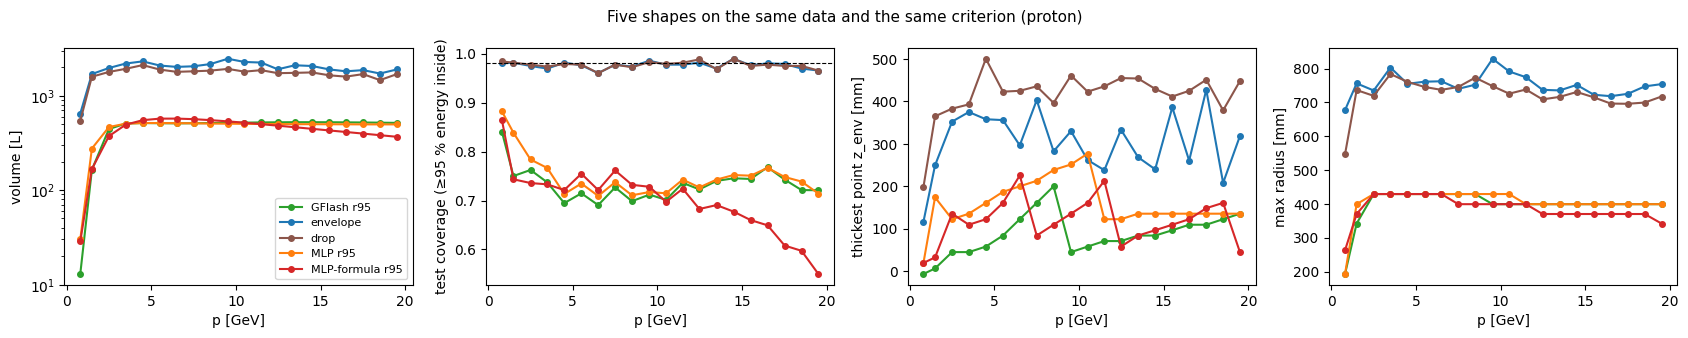

In [10]:
colors = {"GFlash r95": "tab:green", "envelope": "tab:blue", "drop": "tab:brown", "MLP r95": "tab:orange", "MLP-formula r95": "tab:red"}
fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
for name in [o for o in ORDER if o in set(CMP.formula)]:
    g = CMP[CMP.formula == name]
    for a_, col in zip(ax, ["V_L", "cov_test", "z_env", "r_max"]):
        a_.plot(g.p_mean, g[col], "o-", c=colors[name], label=name, ms=4)
for a_, lab in zip(ax, ["volume [L]", "test coverage (≥95 % energy inside)", "thickest point z_env [mm]", "max radius [mm]"]):
    a_.set(xlabel="p [GeV]", ylabel=lab)
ax[0].set_yscale("log"); ax[1].axhline(F_EV, c="k", lw=0.8, ls="--"); ax[0].legend(fontsize=8)
fig.suptitle("Five shapes on the same data and the same criterion (proton)", fontsize=11)
plt.tight_layout(); plt.show()

### 2D map with $(z', r)$ axes, in the same form as the comparison plot of 03

- **Background:** mean energy density of the training data in the given 1 GeV bin ($\log_{10}$, $r$ mirrored).
- **Green dotted:** GFlash $r_{95}$. **Blue:** envelope. **White:** drop. **Orange:** MLP $r_{95}$. **Red dashed:** distilled MLP-formula $r_{95}$.

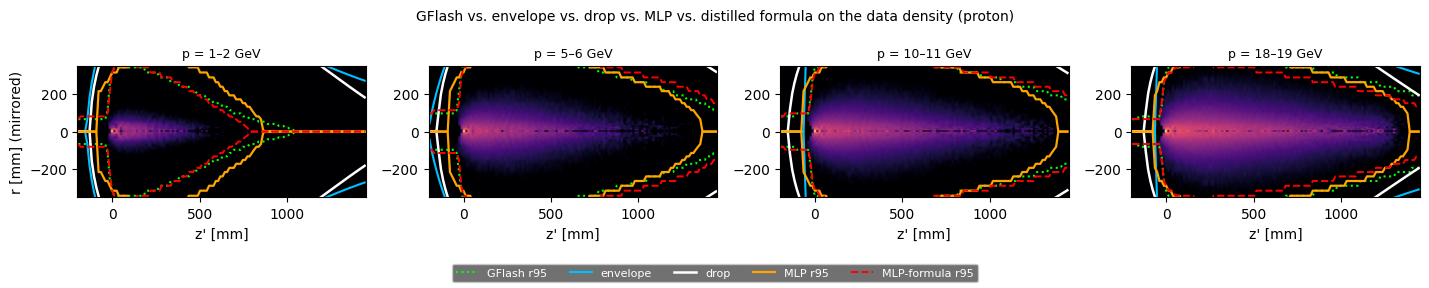

In [11]:
STYLE = {"GFlash r95": dict(c="lime", ls=":", lw=1.5), "envelope": dict(c="deepskyblue", lw=1.5), "drop": dict(c="white", lw=1.8),
         "MLP r95": dict(c="orange", lw=1.6), "MLP-formula r95": dict(c="red", ls="--", lw=1.4)}


def compare_map(sh, p_values=(1, 5, 10, 18), r_show=350, title=""):
    rc_ = RC.cpu().numpy()
    vol = np.exp(LOG_VOL.cpu().numpy())
    h = sh.hits()
    rs = np.linspace(-r_show, r_show, 121)
    fig, axes = plt.subplots(1, len(p_values), figsize=(3.6 * len(p_values), 2.8))
    for ax, p in zip(axes, p_values):
        b = int(p)
        m = (h.p >= b) & (h.p < b + 1)
        H, _, _ = np.histogram2d(h.z[m], h.r[m], bins=[z_edges, R_EDGES.cpu().numpy()], weights=h.w[m])
        d = H / max(h.ev[m].nunique(), 1) / vol
        img = np.log10(np.clip(np.stack([np.interp(np.abs(rs), rc_, row) for row in d], 1), 1e-14, None))
        ax.imshow(img, origin="lower", aspect="auto", extent=[Z_MIN, Z_MAX, -r_show, r_show], cmap="magma",
                  vmin=img.max() - 5, vmax=img.max())
        curves = {name: r95_of(mdl, b + 0.5) for name, mdl in MODELS.items()}
        if b in ENV:
            curves["envelope"] = envelope_r(zc, ENV[b])
        if b in DROP:
            curves["drop"] = drop_radius(zc, DROP[b])
        for name in ORDER:
            if name in curves:
                ax.plot(zc, curves[name], **STYLE[name]); ax.plot(zc, -curves[name], **STYLE[name])
        ax.set_ylim(-r_show, r_show); ax.set_title(f"p = {b}–{b + 1} GeV", fontsize=9); ax.set_xlabel("z' [mm]")
    axes[0].set_ylabel("r [mm] (mirrored)")
    handles = [plt.Line2D([], [], label=n, **STYLE[n]) for n in ORDER if n in set(CMP.formula)]
    fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=8, facecolor="0.3", labelcolor="w")
    fig.suptitle(title, fontsize=10)
    fig.tight_layout(rect=(0, 0.1, 1, 1))
    plt.show()


compare_map(data["train"], title="GFlash vs. envelope vs. drop vs. MLP vs. distilled formula on the data density (proton)")

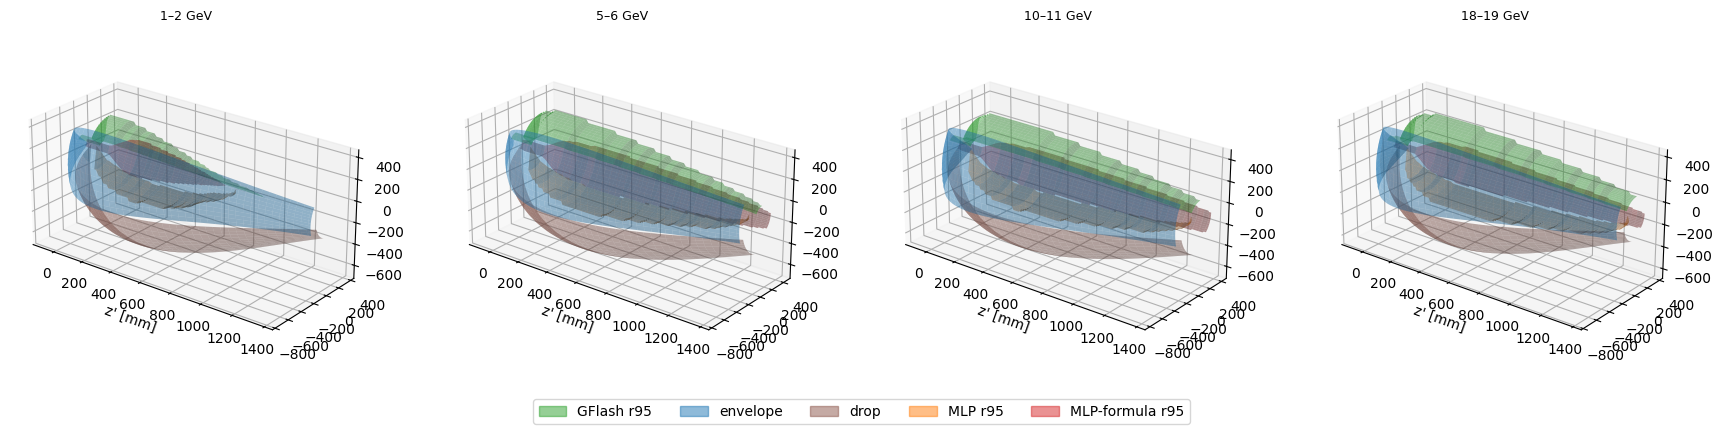

saved: comparison_5shapes.csv, mlp_architecture.csv


In [12]:
# the five bodies side by side in 3D: each body in its own sector, so all of them stay visible
show = [1, 5, 10, 18]
fig = plt.figure(figsize=(4.4 * len(show), 4.2))
for j, b in enumerate(show):
    ax_ = fig.add_subplot(1, len(show), j + 1, projection="3d")
    bodies = {name: r95_of(mdl, b + 0.5) for name, mdl in MODELS.items()}
    if b in ENV:
        bodies["envelope"] = envelope_r(zc, ENV[b])
    if b in DROP:
        bodies["drop"] = drop_radius(zc, DROP[b])
    names = [n for n in ORDER if n in bodies]
    for k, name in enumerate(names):
        f0 = 0.5 * np.pi + 1.5 * np.pi * k / len(names); f1 = 0.5 * np.pi + 1.5 * np.pi * (k + 1) / len(names)
        ax_.plot_surface(*revolve(zc, bodies[name], f0, f1, 12), color=colors[name], alpha=0.45, linewidth=0)
    ax_.set_xlim(-150, 1450); ax_.set_box_aspect((2.2, 1, 1)); ax_.view_init(elev=24, azim=-52)
    ax_.set_title(f"{b}–{b + 1} GeV", fontsize=9); ax_.set_xlabel("z' [mm]")
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=colors[n], alpha=0.5, label=n) for n in ORDER if n in set(CMP.formula)], loc="lower center", ncol=5)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()
CMP.to_csv(f"{OUT_DIR}/{particle}/comparison_5shapes.csv", index=False)
ARCH_TABLE.to_csv(f"{OUT_DIR}/{particle}/mlp_architecture.csv")
print("saved: comparison_5shapes.csv, mlp_architecture.csv")

## 8. The shape-form-particle formula, fitted directly to the data

shape-form-particle builds the average shower shape from physically separate terms – shower + axial term of the primary particle
(range, attenuation, multiple-scattering widening, Bragg rise) + entry spike + end-of-range blob + far halo, see `../ALL-README.md` –
and fits every parameter (a polynomial in ln T) **directly to the simulated hits** by maximum likelihood, with the detector folding of
this notebook. Sections 5–7 distil the network: a few formula families are fitted to the network's maps; here the network is only the benchmark. Nothing is fitted here: the saved final models (`../results/particles/<particle>/`) are loaded and evaluated
on this notebook's test set.

Two metrics:
- **Report metric** (this notebook's `test_nll`). The formula is multiplied by the parameter-free template Ā(z', r), the detector
  acceptance averaged over the incidence angles (the tilted entrance face cuts the body of revolution). The fair reference is the
  report's baseline refitted with the same template ("old formula × Ā").
- **3D metric** of shape-form-particle: the likelihood normalised per event to its own detector slab (between the tilted entrance face
  and the back face). Only models trained in this metric are compared in it: the old formula, the new formula and the MLP, each refitted
  or fine-tuned in 3D.

"saved" next to a recomputed value is the report's own export (before this run) or the number of shape-form-particle (`test_v3.json`).

In [13]:
import json
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "src")))  # particle_shape.py, shapelab.py, protonlab.py
import protonlab
import shapelab

particle = PARTICLES[0]
data = DATA[particle]
OUR = os.path.abspath(os.path.join("..", "results", "particles", particle))   # saved final models of shape-form-particle
PIPE = json.load(open(f"{OUR}/test_v3.json"))                   # its saved test-set numbers (both metrics)
REPORT_SAVED = {'gflash': 18.253603, 'mlp': 18.192236, 'mlp_formula': 18.267671, 'cnn': 18.190821, 'cnn_formula': 18.266161}                                 # the report's saved test NLLs (its exports, before this run)
c0, s0 = shapelab.lnp_center_scale(data)
base_name, base_long, _ = shapelab.REPORT_BASE[particle]       # the report's baseline: GFlash, or the cylinder for the muon
_arch = pd.read_csv(f"{OUT_DIR}/{particle}/mlp_architecture.csv").drop_duplicates("config", keep="last")
_row = _arch[_arch.chosen == "◀"].iloc[-1]
H_MLP, L_MLP = int(_row.hidden), int(_row.n_layers)            # architecture of the report's chosen MLP


def ours(kind, metric, C):
    """A saved model of shape-form-particle: 'new' (the final formula), 'base' (the report's baseline refitted), 'mlp' (the report's
    MLP fine-tuned); metric 'std' = report metric (× Ā), 'slab' = 3D metric."""
    if kind == "new":
        return shapelab.build_final(C, particle, OUR, c0, s0, metric=metric)[0]
    n = PIPE["degrees"][f"base_{metric}"]
    st = torch.load(f"{OUR}/{kind}_{metric}" + (f"_n{n}" if kind == "base" else "") + ".pt", map_location=DEVICE,
                    weights_only=False)["state"]
    if kind == "mlp":
        m = FieldModel(H_MLP, L_MLP)
    else:
        m = Formula(base_long, "core_tail", degree=n, lnp0=c0, lnp_s=s0)
        m = shapelab.WithAcceptance(m, torch.ones(N_Z, N_R)) if metric == "std" else m
        st = {("base." + k[7:] if k.startswith("base.f.") else k[2:] if k.startswith("f.") else k): v for k, v in st.items()}
    m.load_state_dict(st)
    return m.to(DEVICE).eval()


def table(nll, params, saved, ref):
    """Test NLL recomputed here, the saved value, and the paired difference to `ref` (± standard error)."""
    rows = []
    for k, v in nll.items():
        d = np.asarray(nll[ref], dtype=np.float64) - np.asarray(v, dtype=np.float64)
        rows.append({"model": k, "parameters": params[k], "test NLL (here)": float(np.mean(v)), "saved": saved.get(k, np.nan),
                     f"{ref} − model": float(d.mean()), "± SE": float(d.std(ddof=1) / np.sqrt(len(d)))})
    return pd.DataFrame(rows).set_index("model")


def gap_line(m_, key_new, key_old, key_net, saved_gap):
    gap = (m_[key_old] - m_[key_new]) / (m_[key_old] - m_[key_net])
    print(f"gap closed: {100 * gap:.0f} % (saved: {100 * saved_gap:.0f} %);  the new formula reaches "
          f"{100 * np.exp(m_[key_net] - m_[key_new]):.1f} % of the fine-tuned network's likelihood per deposit")

### 8.1 Accuracy in the report metric

All models on the same test events. Gap closed = (old formula × Ā − new formula) / (old formula × Ā − fine-tuned MLP).

In [14]:
new_std, base_std, mlp_std = (ours(k, "std", globals()) for k in ("new", "base", "mlp"))
NET, FORM = NETS[particle], FORMULAS[particle]                 # the report's MLP and its distilled formula (sections 4–5)
ex_base = torch.load(f"{OUT_DIR}/{particle}/export_{base_name}.pt", weights_only=False)
nll = {f"report baseline ({base_name})": ex_base["test_nll"], "report MLP": nll_net, "report MLP-distilled formula": nll_f}
saved = {f"report baseline ({base_name})": REPORT_SAVED[base_name], "report MLP": REPORT_SAVED["mlp"],
         "report MLP-distilled formula": REPORT_SAVED["mlp_formula"]}
params = {f"report baseline ({base_name})": ex_base["n_params"], "report MLP": sum(p.numel() for p in NET.parameters()),
          "report MLP-distilled formula": FORM.n_params()}
if "mlp" == "cnn":                                          # the CNN notebook also shows the report's MLP (05)
    nll["report MLP"], saved["report MLP"], params["report MLP"] = test_nll(MLP, data["test"]), REPORT_SAVED["mlp"], sum(p.numel() for p in MLP.parameters())
nll.update({"old formula × Ā (refit)": test_nll(base_std, data["test"]), "new formula × Ā": test_nll(new_std, data["test"]),
            "MLP fine-tuned": test_nll(mlp_std, data["test"])})
saved.update({"old formula × Ā (refit)": PIPE["nll"]["std:base_acc"], "new formula × Ā": PIPE["nll"]["std:new"], "MLP fine-tuned": PIPE["nll"]["std:mlp_ft"]})
params.update({"old formula × Ā (refit)": base_std.n_params(), "new formula × Ā": new_std.n_params(),
               "MLP fine-tuned": sum(p.numel() for p in mlp_std.parameters())})
display(table(nll, params, saved, "new formula × Ā").round(4))
m_ = {k: float(np.mean(v)) for k, v in nll.items()}
gap_line(m_, "new formula × Ā", "old formula × Ā (refit)", "MLP fine-tuned", PIPE["gap_closed"]["std:new"])

,parameters,test NLL (here),saved,new formula × Ā − model,± SE
model,,,,,
report baseline (gflash),45,18.2536,18.2536,-0.0596,0.0020
report MLP,881,18.1922,18.1922,0.0018,0.0005
report MLP-distilled formula,21,18.2677,18.2677,-0.0737,0.0020
old formula × Ā (refit),45,18.2331,18.2331,-0.0391,0.0016
new formula × Ā,143,18.1940,18.1940,0.0000,0.0000
MLP fine-tuned,881,18.1898,18.1898,0.0042,0.0004


gap closed: 90 % (saved: 90 %);  the new formula reaches 99.6 % of the fine-tuned network's likelihood per deposit


### 8.2 Accuracy in the 3D metric (shape-form-particle's own metric)

The same test events with the likelihood normalised to each event's detector slab. A fresh copy of the unchanged common code is used,
with only `event_nll` replaced by its slab-normalised version (`shapelab.SLAB_NLL_SRC`).

In [15]:
C3 = protonlab.load_common_for(particle, OUT_DIR=OUT_DIR)       # the 00_common definitions in a separate namespace ...
exec(shapelab.SLAB_GEOM_SRC, C3)
exec(shapelab.SLAB_NLL_SRC, C3)                                  # ... with the likelihood normalised to each event's detector slab
names = {"old formula (3D refit)": "base", "new formula": "new", "MLP fine-tuned (3D)": "mlp"}
models3 = {k: ours(v, "slab", C3) for k, v in names.items()}
nll3 = {k: C3["test_nll"](m, data["test"]) for k, m in models3.items()}
params3 = {k: (m.n_params() if hasattr(m, "n_params") else sum(p.numel() for p in m.parameters())) for k, m in models3.items()}
saved3 = dict(zip(nll3, [PIPE["nll"]["slab:base"], PIPE["nll"]["slab:new"], PIPE["nll"]["slab:mlp_ft"]]))
display(table(nll3, params3, saved3, "new formula").round(4))
m3 = {k: float(np.mean(v)) for k, v in nll3.items()}
gap3 = (m3["old formula (3D refit)"] - m3["new formula"]) / (m3["old formula (3D refit)"] - m3["MLP fine-tuned (3D)"])
print(f"gap closed (3D): {100 * gap3:.0f} % (saved: {100 * PIPE['gap_closed']['slab:new']:.0f} %)")
if particle == "pion":
    print("note: the pion's 3D MLP is degenerate (almost all of its mass lies outside the detector slabs), so the 3D gap is not reliable")

device: cuda | data: /home/user/data/simulations/regression-proton/ | output: results


,parameters,test NLL (here),saved,new formula − model,± SE
model,,,,,
old formula (3D refit),45,18.2003,18.2003,-0.0343,0.0015
new formula,143,18.1660,18.1660,0.0000,0.0000
MLP fine-tuned (3D),881,18.1614,18.1614,0.0047,0.0005


gap closed (3D): 88 % (saved: 88 %)


### 8.3 The fitted formula

The formula of this particle with the fitted values (3D metric), as written in `../ALL-README.md` (all coefficients:
`../results/particles/<particle>/formula_coefficients_slab.csv`; the full card: `formula.md` in the same folder).

In [16]:
name = {"electron": "Electron", "muon": "Muon", "pion": "Pion", "proton": "Proton"}[particle]
txt = open(os.path.join("..", "ALL-README.md"), encoding="utf-8").read()
i = txt.index(f"**{name}** (m =")
display(Markdown(txt[i:min(k for k in (txt.find("\n**", i + 5), txt.find("<!-- KEPLETEK:END", i)) if k > 0)]))

**Proton** (m = 938.3 MeV; polynomial degree and number of parameters: n = 6, 143)

`ρ(z', r | p) = w_zápor·S + w_nyom·U + w_csúcs·D + w_folt·E + w_távoli·H`

- Shower depth profile, plateau: `L(z') ∝ σ((z' − z_s)/w1)·σ((ℓ − z')/w2)·e^(κ·z'/1 m)` (values below).
- Shower cross-section: `T(r│z') = f_core·Gauss(r; σ) + f_body·Cauchy(r; R) + f_halo·e^(−r/λ)/(2πλ(r + 1 mm))`; σ, R, λ and the fractions vary with depth (below at z' = 100 mm).
- Axial term: range `R(T) = 757 mm · (T/GeV)^1.78 − 36.5 mm` (smoothly floored at ~1 mm); start `σ((z' − 24.1 mm)/4 mm)`, end `σ((R − z')/w_R)` with w_R = 0.0579·R + 3 mm; attenuation `e^(−z'/266 mm)·e^(−2.46·z'/R)`; Bragg rise `(1 − z'/R + 0.03)^(−0.804)`; width `σ(z')² = (18.5 mm)² + (285 mm · (z'/1 m)^2.37 / βp)²`; delta-electron halo `e^(−r/81.5 mm)/(2π·81.5 mm·(r + 1 mm))` (its share below).
- End-of-range blob: Gaussian, σ_z = 76.3 mm, σ_r = 81.1 mm.
- Entry spike: Gaussian (position and widths below). Far halo: `H ∝ σ(z'/10 mm)·e^(−z'/962 mm)/(r + 1 cm)`.

| | p = 1 GeV/c | p = 5 GeV/c | p = 20 GeV/c |
|---|---:|---:|---:|
| T (kinetic energy) | 0.433 GeV | 4.15 GeV | 19.1 GeV |
| energy share: shower | 14.9% | 73.6% | 81.1% |
| energy share: track | 60.5% | 21.1% | 16.8% |
| energy share: spike | 23.6% | 4.87% | 2.12% |
| energy share: blob | 0.671% | < 0.01% | < 0.01% |
| energy share: far halo | 0.383% | 0.408% | < 0.01% |
| shower start z_s / rise w1 | −7.12 / 123 mm | 22.3 / 86.3 mm | 80.7 / 80.2 mm |
| shower end ℓ / fall-off w2 | 132 / 198 mm | 863 / 378 mm | 1330 / 76.2 mm |
| slow slope κ | −3.02 /m | −2.72 /m | −2.65 /m |
| core σ / Cauchy R / halo λ (z' = 100 mm) | 84.4 / 121 / 227 mm | 58.8 / 71 / 207 mm | 38.9 / 77.6 / 203 mm |
| fractions core / body / halo (z' = 100 mm) | 0.08 / 0.87 / 0.05 | 0.08 / 0.80 / 0.13 | 0.13 / 0.76 / 0.10 |
| axial-term range R(T) | 135 mm | 9485 mm | 143749 mm |
| delta-halo share | 3.94% | 33.4% | 20.4% |
| spike position / σ_z / σ_r | −3.17 / 13.7 / 10.1 mm | −7.75 / 22.1 / 11.5 mm | −18.5 / 23.8 / 11.6 mm |


### 8.4 Profiles and the true shape

The profile plots of this notebook, now with the new formula (report metric, × Ā), and the true (de-convolved) shape of the formula.

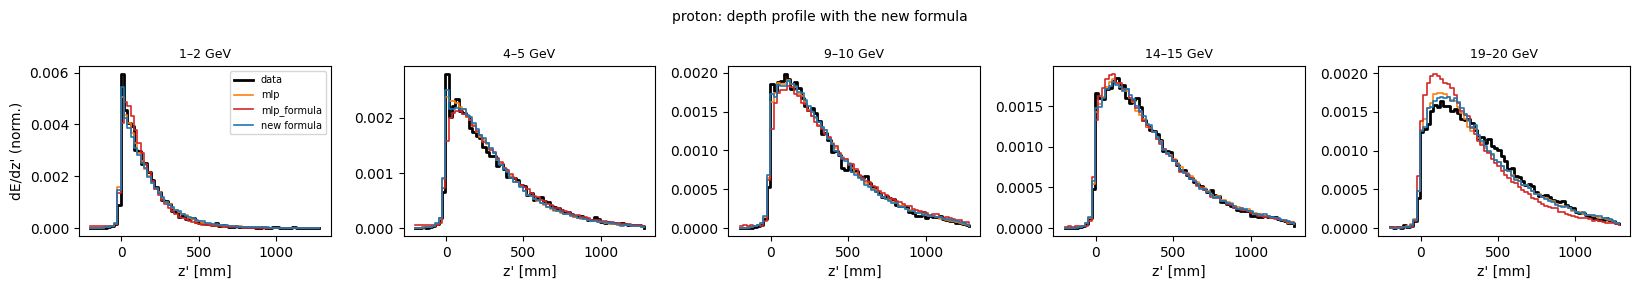

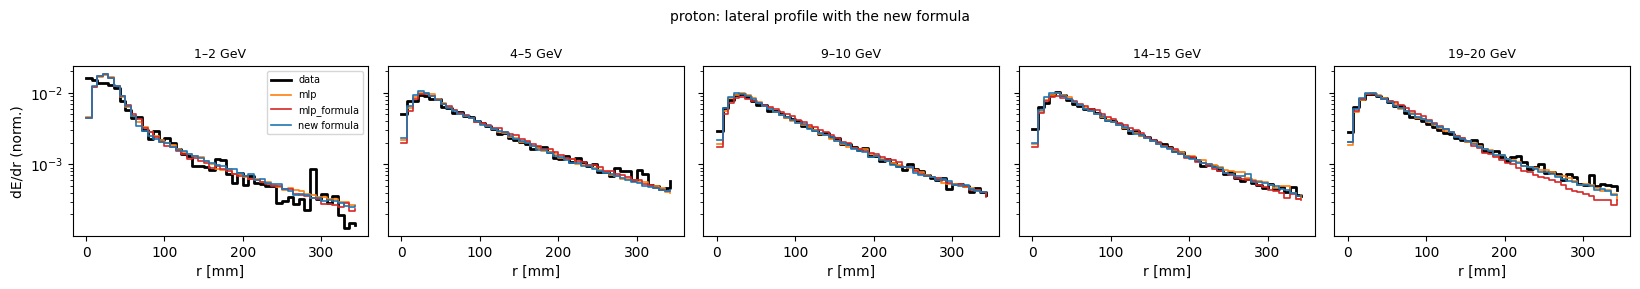

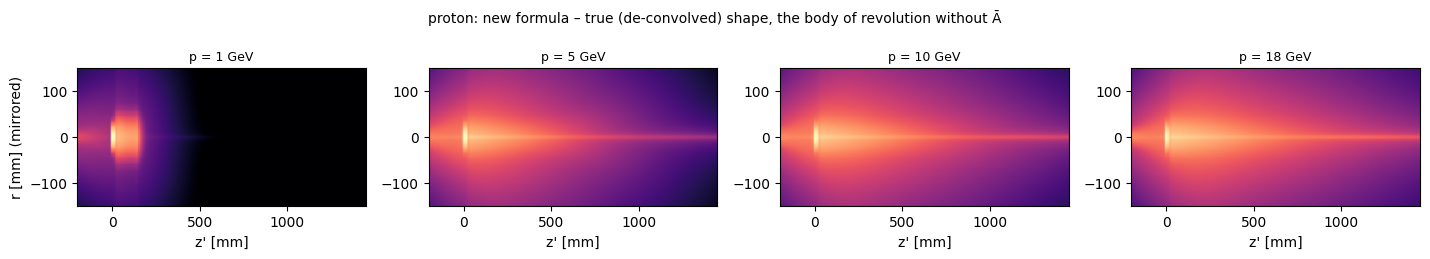

In [17]:
COLORS["new formula"] = "tab:blue"
samples["new formula"] = sample_folded(new_std, data["test"])
profile_plot(hits, samples, "z", f"{particle}: depth profile with the new formula")
profile_plot(hits, samples, "r", f"{particle}: lateral profile with the new formula")
shape_map(new_std.base, title=f"{particle}: new formula – true (de-convolved) shape, the body of revolution without Ā")

### 8.5 The r95 region in the unified comparison of section 7

The 95 % region of the new formula's average map (the same definition and coverage test as for the network), added to the
comparison table and the 2D map of section 7.

,V_L,cov_test,z_env,r_max
formula,,,,
GFlash r95,469.968,0.733,85.100,396.597
envelope,1965.268,0.976,303.100,751.476
drop,1707.318,0.977,414.625,722.082
MLP r95,465.902,0.750,158.650,402.453
MLP-formula r95,439.514,0.702,116.700,385.484
new formula r95,494.415,0.767,216.025,419.109


saved (shape-form-particle, r95 new formula): V = 494.4 L, coverage 0.77


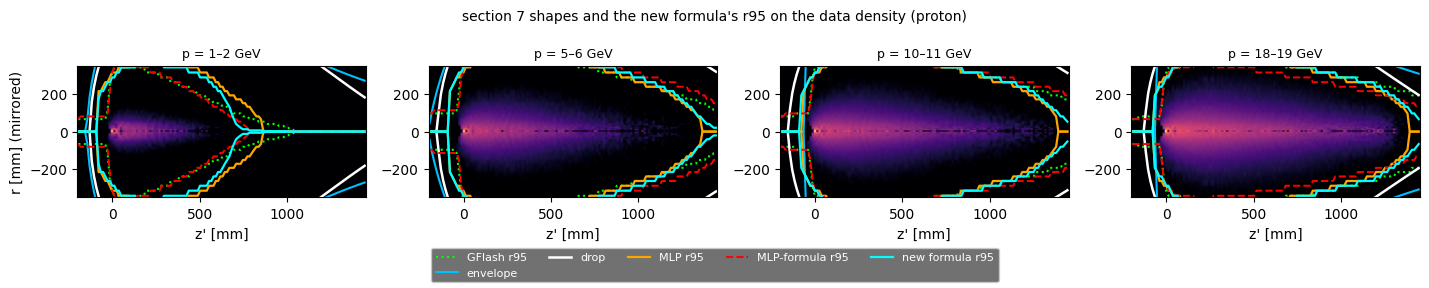

In [18]:
rows = []
for b in range(20):
    te = (data["test"].ev["bin"] == b).nonzero().squeeze(1)
    if len(te) == 0:
        continue
    pm = float(data["test"].ev["p"][te].mean())
    r95 = r95_of(new_std, pm)
    rows.append({"bin": b, "p_mean": pm, "formula": "new formula r95", **stats(grid_fn(r95)),
                 "V_L": float(np.sum(np.pi * r95 ** 2) * DZ) / 1e6, "cov_test": profile_coverage(deposits(data["test"].subset(te)), grid_fn(r95))})
CMP = pd.concat([CMP, pd.DataFrame(rows)], ignore_index=True)
MODELS["new formula r95"] = new_std
ORDER = ORDER + ["new formula r95"]
STYLE["new formula r95"] = dict(c="cyan", lw=1.6)
colors["new formula r95"] = "tab:cyan"
display(CMP.groupby("formula")[["V_L", "cov_test", "z_env", "r_max"]].mean().reindex([o for o in ORDER if o in set(CMP.formula)]).round(3))
sh_ = {s["shape"]: s for s in json.load(open(f"{OUR}/shapes.json"))["shapes"]}
print(f"saved (shape-form-particle, r95 new formula): V = {sh_['r95 new formula']['V']:.1f} L, coverage {sh_['r95 new formula']['cov']:.2f}")
compare_map(data["train"], title=f"section 7 shapes and the new formula's r95 on the data density ({particle})")

### 8.6 Export for the summary notebook

The new formula (report metric) is exported like every model of the report, so that `07_summary` can include it. `export` counts every
coefficient slot of the formula; the number of free parameters is stored instead.

In [19]:
export(particle, "new_formula", new_std, data, f"shape-form-particle formula ({particle}): see ../ALL-README.md")
_p = f"{OUT_DIR}/{particle}/export_new_formula.pt"
_e = torch.load(_p, weights_only=False)
_e["n_params"] = int(new_std.n_params())
torch.save(_e, _p)

exported proton/new_formula: test NLL = 18.1940


**What to look for:** the recomputed test NLLs agree with the saved numbers; the new formula lies between the old formula and the
network and closes most of the gap; in the profiles it follows the data where a single shower term cannot (primary particle, entrance,
lateral tail).